# Tutorial 3: Explainable Machine Learning Hazard Susceptibility

Training CatBoost, XGBoost, and Random Forest with Spatial Block Cross-Validation and SHAP interpretability using inundation_risk.hazard_ml.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from inundation_risk.spatial_features import read_geotiff, compute_slope_aspect, compute_twi, extract_stream_network, compute_distance_to_stream
from inundation_risk.hazard_ml import build_ml_dataset, HazardModelTrainer, compute_shap_explanations

## 2. Prepare Factor Rasters and Dataset

In [2]:
dem, _ = read_geotiff('../benchmarks/malang_raya/data/malang_dem_sample.tif')
accum, _ = read_geotiff('../benchmarks/malang_raya/data/malang_flow_accum_sample.tif')
slope, _ = compute_slope_aspect(dem, 30.0)
twi = compute_twi(accum, slope, 30.0)
streams = extract_stream_network(accum, threshold_cells=500)
dist_stream = compute_distance_to_stream(streams, 30.0)

factors = {'dem': dem, 'slope': slope, 'twi': twi, 'dist_stream': dist_stream}
flood_mask = (twi > np.nanpercentile(twi, 80)) & (slope < np.nanpercentile(slope, 30))
X, y, coords = build_ml_dataset(factors, flood_mask, ratio_negative=1.0, random_state=42)
print('Dataset samples:', len(X))

Dataset samples: 2680


## 3. Spatial Block Cross-Validation

In [3]:
trainer = HazardModelTrainer(algorithm='random_forest', random_state=42)
metrics = trainer.evaluate_spatial_cv(X, y, coords, n_splits=5)
print('Spatial Block CV Results:', metrics)

Spatial Block CV Results: {'roc_auc_mean': 1.0, 'roc_auc_std': 0.0, 'pr_auc_mean': 1.0, 'f1_mean': 0.9993220338983051, 'accuracy_mean': 0.9996478873239436, 'brier_score_mean': 0.00043884055207787107, 'n_splits': 5}


## 4. Generate Hazard Susceptibility Map

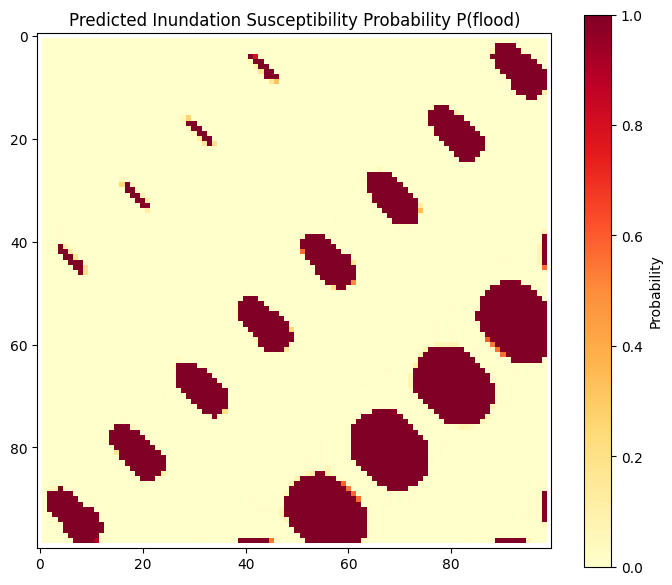

In [4]:
trainer.fit(X, y)
hazard_map = trainer.predict_spatial_raster(factors, list(factors.keys()))

plt.figure(figsize=(7, 6))
plt.imshow(hazard_map, cmap='YlOrRd', vmin=0, vmax=1)
plt.title('Predicted Inundation Susceptibility Probability P(flood)')
plt.colorbar(label='Probability')
plt.tight_layout()
plt.show()